# Выбор локации для скважины в компании "ГлавРосГосНефть"

В добывающей компании «ГлавРосГосНефть» нужно решить, где бурить новую скважину.

Предоставлены пробы нефти в трёх регионах: в каждом 100 000 месторождений, где измерили качество нефти и объём её запасов. Нужно построить модель машинного обучения, которая поможет определить регион, где добыча принесёт наибольшую прибыль. Нужно проанализировать возможную прибыль и риски техникой Bootstrap.

Шаги для выбора локации:

- В избранном регионе ищут месторождения, для каждого определяют значения признаков;
- Строят модель и оценивают объём запасов;
- Выбирают месторождения с самым высокими оценками значений. Количество месторождений зависит от бюджета компании и стоимости разработки одной скважины;
- Прибыль равна суммарной прибыли отобранных месторождений.

## Первичный анализ данных

In [1]:
#Импорт необходимых библиотек 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

In [2]:
#Загрузка необходимых данных и сохранение в соответствующие датафреймы
geo_df1 = pd.read_csv('/datasets/geo_data_0.csv')
geo_df2 = pd.read_csv('/datasets/geo_data_1.csv')
geo_df3 = pd.read_csv('/datasets/geo_data_2.csv')

In [3]:
#Вывожу первые 5 строк датафрейма 'geo_df1' и общую информацию о нем
display(geo_df1.head(5))
geo_df1.info()

,id,f0,f1,f2,product
0,txEyH,0.705745,-0.497823,1.221170,105.280062
1,2acmU,1.334711,-0.340164,4.365080,73.037750
2,409Wp,1.022732,0.151990,1.419926,85.265647
3,iJLyR,-0.032172,0.139033,2.978566,168.620776
4,Xdl7t,1.988431,0.155413,4.751769,154.036647


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 5 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   id       100000 non-null  object 
 1   f0       100000 non-null  float64
 2   f1       100000 non-null  float64
 3   f2       100000 non-null  float64
 4   product  100000 non-null  float64
dtypes: float64(4), object(1)
memory usage: 3.8+ MB


In [4]:
#Вывожу основные статистические параметры датафрейма geo_df1
geo_df1.describe()

,f0,f1,f2,product
count,100000.000000,100000.000000,100000.000000,100000.000000
mean,0.500419,0.250143,2.502647,92.500000
std,0.871832,0.504433,3.248248,44.288691
min,-1.408605,-0.848218,-12.088328,0.000000
25%,-0.072580,-0.200881,0.287748,56.497507
50%,0.502360,0.250252,2.515969,91.849972
75%,1.073581,0.700646,4.715088,128.564089
max,2.362331,1.343769,16.003790,185.364347


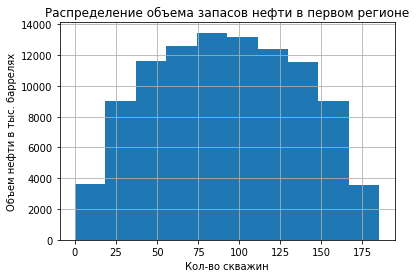

In [5]:
#Строю гистограмму распределения объема запасов нефти в первом регионе
geo_df1['product'].hist(); 
plt.title('Распределение объема запасов нефти в первом регионе')
plt.xlabel('Кол-во скважин')
plt.ylabel('Объем нефти в тыс. баррелях')
plt.show()

**Вывод:** В датафрейме df_1 содержатся данные геологоразведки в первом регионе. Всего в датафрейме 100000 значений и 5 признаков:
- id — уникальный идентификатор скважины;
- f0, f1, f2 — три признака точек;
- product — объём запасов в скважине (тыс. баррелей).

Все столбцы имеют верный тип данных. 
В первом регионе средний объём запасов в скважинах составляет ~92.5 тыс. баррелей, при этом стандартное отклонение равно ~44.3 тыс. баррелей. Высокое значение стандартного отклонения указывает на значительную неоднородность распределения запасов: часть скважин может содержать существенно больше нефти, а часть — меньше среднего уровня. Максимальный объём нефти в одной скважине достигает 185.36 тыс. баррелей. Более того, на гистограмме видно, что большинство скважин имеет объём запасов нефти в пределах 50–130 тыс. баррелей.

In [6]:
#Вывожу первые 5 строк датафрейма 'geo_df2' и общую информацию о нем
display(geo_df2.head(5))
geo_df2.info()

,id,f0,f1,f2,product
0,kBEdx,-15.001348,-8.276000,-0.005876,3.179103
1,62mP7,14.272088,-3.475083,0.999183,26.953261
2,vyE1P,6.263187,-5.948386,5.001160,134.766305
3,KcrkZ,-13.081196,-11.506057,4.999415,137.945408
4,AHL4O,12.702195,-8.147433,5.004363,134.766305


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 5 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   id       100000 non-null  object 
 1   f0       100000 non-null  float64
 2   f1       100000 non-null  float64
 3   f2       100000 non-null  float64
 4   product  100000 non-null  float64
dtypes: float64(4), object(1)
memory usage: 3.8+ MB


In [7]:
#Вывожу основные статистические параметры датафрейма geo_df2
geo_df2.describe()

,f0,f1,f2,product
count,100000.000000,100000.000000,100000.000000,100000.000000
mean,1.141296,-4.796579,2.494541,68.825000
std,8.965932,5.119872,1.703572,45.944423
min,-31.609576,-26.358598,-0.018144,0.000000
25%,-6.298551,-8.267985,1.000021,26.953261
50%,1.153055,-4.813172,2.011479,57.085625
75%,8.621015,-1.332816,3.999904,107.813044
max,29.421755,18.734063,5.019721,137.945408


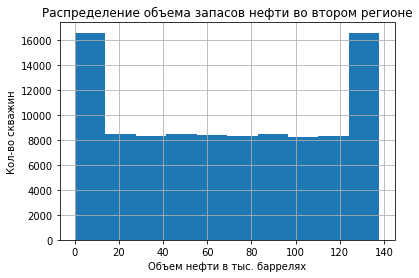

In [8]:
#Строю гистограмму распределения объема запасов нефти во втором регионе
geo_df2['product'].hist(); 
plt.title('Распределение объема запасов нефти во втором регионе')
plt.xlabel('Объем нефти в тыс. баррелях')
plt.ylabel('Кол-во скважин')
plt.show()

**Вывод:** В датафрейме df_2 содержатся данные геологоразведки во втором регионе. Всего в датафрейме 100000 значений и 5 признаков:
- id — уникальный идентификатор скважины;
- f0, f1, f2 — три признака точек;
- product — объём запасов в скважине (тыс. баррелей).

Все столбцы имеют верный тип данных. Во втором регионе средний объём запасов в скважинах составляет ~68.8 тыс. баррелей, при стандартном отклонении ~45.9 тыс. баррелей. Максимальный объём достигает ~137.9 тыс. баррелей. По сравнению с первым регионом здесь средние объёмы запасов ниже, а распределение — более неоднородное. На гистограмме чётко видно две группы: значительное количество скважин полностью пустые и, напротив, заметная доля скважин с очень высоким объёмом нефти. Такое распределение указывает на повышенный риск при разработке региона: велика вероятность пробурить «пустую» скважину, хотя потенциальный выигрыш при успешной добыче также выше.

In [9]:
#Вывожу первые 5 строк датафрейма 'geo_df3' и общую информацию о нем
display(geo_df3.head(5))
geo_df3.info()

,id,f0,f1,f2,product
0,fwXo0,-1.146987,0.963328,-0.828965,27.758673
1,WJtFt,0.262778,0.269839,-2.530187,56.069697
2,ovLUW,0.194587,0.289035,-5.586433,62.871910
3,q6cA6,2.236060,-0.553760,0.930038,114.572842
4,WPMUX,-0.515993,1.716266,5.899011,149.600746


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 5 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   id       100000 non-null  object 
 1   f0       100000 non-null  float64
 2   f1       100000 non-null  float64
 3   f2       100000 non-null  float64
 4   product  100000 non-null  float64
dtypes: float64(4), object(1)
memory usage: 3.8+ MB


In [10]:
#Вывожу основные статистические параметры датафрейма geo_df3
geo_df3.describe()

,f0,f1,f2,product
count,100000.000000,100000.000000,100000.000000,100000.000000
mean,0.002023,-0.002081,2.495128,95.000000
std,1.732045,1.730417,3.473445,44.749921
min,-8.760004,-7.084020,-11.970335,0.000000
25%,-1.162288,-1.174820,0.130359,59.450441
50%,0.009424,-0.009482,2.484236,94.925613
75%,1.158535,1.163678,4.858794,130.595027
max,7.238262,7.844801,16.739402,190.029838


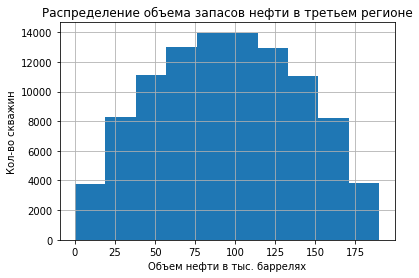

In [11]:
#Строю гистограмму распределения объема запасов нефти в третьем регионе
geo_df3['product'].hist(); 
plt.title('Распределение объема запасов нефти в третьем регионе')
plt.xlabel('Объем нефти в тыс. баррелях')
plt.ylabel('Кол-во скважин')
plt.show()

**Вывод:** В датафрейме df_3 содержатся данные геологоразведки в третьем регионе. Всего в датафрейме 100000 значений и 5 признаков:
- id — уникальный идентификатор скважины;
- f0, f1, f2 — три признака точек;
- product — объём запасов в скважине (тыс. баррелей).

Все столбцы имеют верный тип данных. В третьем регионе средний объём запасов в скважинах составляет ~95 тыс. баррелей при стандартном отклонении ~44.7 тыс. баррелей. Максимальный объём достигает 190 тыс. баррелей. По сравнению с первым регионом средний показатель выше примерно на 3 тыс. баррелей, а форма распределения схожа: большинство скважин имеют объём запасов в пределах 60–130 тыс. баррелей. Это указывает на более стабильное распределение запасов и снижает риск бурения «пустых» скважин по сравнению со вторым регионом.

In [12]:
#Подсчет кол-ва явных дубликатов в трех датафреймах
print('Кол-во явных дубликатов в датафрейме geo_df1:', geo_df1.duplicated(subset=['id', 'f0', 'f1', 'f2']).sum())
print('Кол-во явных дубликатов в датафрейме geo_df2:', geo_df2.duplicated(subset=['id', 'f0', 'f1', 'f2']).sum())
print('Кол-во явных дубликатов в датафрейме geo_df3:', geo_df3.duplicated(subset=['id', 'f0', 'f1', 'f2']).sum())

Кол-во явных дубликатов в датафрейме geo_df1: 0
Кол-во явных дубликатов в датафрейме geo_df2: 0
Кол-во явных дубликатов в датафрейме geo_df3: 0


**Вывод:** В датафреймах отсутствуют явные дубликаты. 

## Обучение и проверка модели

In [13]:
#Создание константы RANDOM_STATE
RANDOM_STATE = 42

#Функция для обучения модели
def predict_oil_vols(data):
    #Разделяем целевую переменную от остальных признаков, убираем 'id'
    X = data.drop(columns=['id', 'product'])
    y = data['product']
    
    #Разделяем на тренировочную и валидационную выборки
    X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.25, random_state=RANDOM_STATE)

    #Обучаем модель линейной регрессии и делаем предсказания
    model_lr = LinearRegression()
    model_lr.fit(X_train, y_train)
    predictions = model_lr.predict(X_valid)
    
    #Созраняем признаки и предсказания в отдельный датафрейм
    X_pred = X_valid.copy()
    X_pred['Истинные значения'] = y_valid.copy()
    X_pred['Предсказанные значения'] = predictions
    
    #Вывожу полученный датафрейм 
    return X_pred

#Функция для проверки модели
def rmse_calc(data):
    #Считаем среднеквадратичную ошибку модели
    rmse = mean_squared_error(data['Истинные значения'], data['Предсказанные значения'], squared=False)
    print(f"Среднее значение предсказаний = {data['Предсказанные значения'].mean():.2f}")
    print(f"Среднее значение истинных значений = {data['Истинные значения'].mean():.2f}")
    return f'Значение среднеквадратичной ошибки = {rmse:.2f}'

In [14]:
#Делаем предсказания для первого региона
geo_df1_pred = predict_oil_vols(geo_df1)
display(geo_df1_pred)
#Вывожу результаты проверки модели для первого региона
rmse_calc(geo_df1_pred)

,f0,f1,f2,Истинные значения,Предсказанные значения
75721,0.599283,-0.557623,2.121187,122.073350,101.901017
80184,0.739017,-0.463156,-1.347584,48.738540,78.217774
19864,1.422743,-0.534917,3.718798,131.338088,115.266901
76699,1.580244,-0.238458,2.805149,88.327757,105.618618
92991,0.918974,0.023961,2.598575,36.959266,97.980185
...,...,...,...,...,...
21271,0.754647,-0.512213,2.610771,148.821520,105.076959
34014,-0.062056,0.516884,0.714446,123.454003,74.768176
81355,0.593769,-0.425260,-0.525017,91.945213,82.544397
65720,0.198209,0.453940,1.497557,149.295563,81.826689


Среднее значение предсказаний = 92.40
Среднее значение истинных значений = 92.33


'Значение среднеквадратичной ошибки = 37.76'

**Вывод:** В первом регионе средний предсказанный объём запасов нефти составил 92.4 тыс. баррелей, что близко к среднему значению фактических данных — 92.33 тыс. баррелей. При этом среднеквадратичная ошибка модели (RMSE) составляет 37.76 тыс. баррелей, что отражает среднее отклонение предсказаний от реальных значений.

In [15]:
#Делаем предсказания для второго региона
geo_df2_pred = predict_oil_vols(geo_df2)
display(geo_df2_pred)
#Вывожу результаты проверки модели для второго региона
rmse_calc(geo_df2_pred)

,f0,f1,f2,Истинные значения,Предсказанные значения
75721,6.078076,0.084568,0.002957,0.000000,0.844738
80184,16.462386,2.712946,1.993030,53.906522,52.921612
19864,7.051898,0.766983,4.990194,134.766305,135.110385
76699,-0.240045,-0.380804,3.999693,107.813044,109.494863
92991,13.350111,-8.558281,0.002010,0.000000,-0.047292
...,...,...,...,...,...
21271,8.141417,-0.832158,4.001976,107.813044,108.351600
34014,16.601751,-8.141232,2.010371,53.906522,53.604049
81355,14.674777,-5.633890,1.004171,26.953261,26.708734
65720,-1.381118,-5.464254,4.001648,110.992147,109.823087


Среднее значение предсказаний = 68.71
Среднее значение истинных значений = 68.73


'Значение среднеквадратичной ошибки = 0.89'

**Вывод:** Во втором регионе средний предсказанный объём запасов нефти составил 68.71 тыс. баррелей, что практически совпадает со средним фактическим значением (68.73 тыс. баррелей). Значение RMSE = 0.89 тыс. баррелей указывает на высокую точность модели при прогнозировании. Однако при интерпретации результатов важно учитывать сильную неоднородность распределения запасов нефти по скважинам: в ряде скважин объёмы значительно выше или ниже среднего уровня.

In [16]:
#Делаем предсказания для третьего региона
geo_df3_pred = predict_oil_vols(geo_df3)
display(geo_df3_pred)
#Вывожу результаты проверки модели для третьего региона
rmse_calc(geo_df3_pred)

,f0,f1,f2,Истинные значения,Предсказанные значения
75721,2.111118,-1.679773,3.112240,117.441301,98.301916
80184,0.734759,0.747788,3.670879,47.841249,101.592461
19864,-2.513109,0.844631,-4.922889,45.883483,52.449099
76699,-2.035301,-1.522988,5.072839,139.014608,109.922127
92991,2.744145,1.429952,-1.372661,84.004276,72.411847
...,...,...,...,...,...
21271,-1.532677,0.365315,3.840436,40.797226,102.764169
34014,1.381244,1.168552,2.262261,87.144239,93.431823
81355,2.902487,0.839203,-2.817721,52.039812,64.098390
65720,0.942093,-1.424641,0.567559,136.961454,83.764135


Среднее значение предсказаний = 94.77
Среднее значение истинных значений = 95.15


'Значение среднеквадратичной ошибки = 40.15'

**Вывод:** В третьем регионе средний предсказанный объём запасов нефти оказался наибольшим и составил 94.8 тыс. баррелей, что практически совпадает со средним фактическим значением (95.2 тыс. баррелей). Однако значение RMSE = 40.15 тыс. баррелей свидетельствует о значительно меньшей точности модели по сравнению с первым регионом: разброс предсказаний вокруг истинных значений здесь гораздо выше.

## Подготовка данных для расчёта прибыли

In [17]:
#Общий бюджет отображен в тыс.рублях
budget = 10000000
#Цена одной единицы продукта в тыс.рублях
unit_price = 450
#Количество выбираемых точек для разработки
n_points = 200
#Расчет минимального объема сырья для безубыточной разработки новой скважины
min_vol = budget/(unit_price*n_points)
print('Минимальный объем сырья для безубыточной разработки новой скважины =', min_vol)
#Список со средними значениями объемов нефти в трех регионах
l = [92.33, 68.73, 95.15]
for i in range(len(l)):
    print('Средний объем нефти в регионе', i+1, '=', l[i])

Минимальный объем сырья для безубыточной разработки новой скважины = 111.11111111111111
Средний объем нефти в регионе 1 = 92.33
Средний объем нефти в регионе 2 = 68.73
Средний объем нефти в регионе 3 = 95.15


**Вывод:** Минимальный объём сырья для безубыточной разработки новой скважины составляет 111.11 тыс. баррелей. Средний фактический объём в каждом регионе ниже этой величины. Это означает, что при случайном выборе скважин прибыль не гарантирована, и для её обеспечения необходимо отобрать наиболее перспективный регион.

## Расчёт прибыли и рисков 

In [18]:
#Функция для расчета прибыли в тыс.руб. по выбранным скважинам и предсказаниям модели
def profit_calc(df):
    df = df.sort_values(by='Предсказанные значения', ascending=False).head(200)
    result = ((df['Истинные значения'] * unit_price).sum()) - 10000000
    return result
#Вывод расчетов прибыли в тыс.руб. по предсказаниям модели для трех регионов
print('Прибыль в первом регионе', profit_calc(geo_df1_pred))
print('Прибыль во втором регионе', profit_calc(geo_df2_pred))
print('Прибыль в третьем регионе', profit_calc(geo_df3_pred))

Прибыль в первом регионе 3359141.11446218
Прибыль во втором регионе 2415086.696681503
Прибыль в третьем регионе 2598571.759374112


In [19]:
#Функция для расчета бутстрепа
def bootstrap_calc(df):
    profits = []
    for i in range(1000):
        subsample = df.sample(n=500, replace=True)
        profits.append(profit_calc(subsample))
    return profits
#Функция для проверки на убыток
def loss_risk_calc(a):
    risk = (a < 0).mean()
    if risk < 0.025:
        return('Регион подходит — риск меньше 2.5%')
    else:
        return('Регион НЕ подходит — риск выше нормы')

In [20]:
#Расчеты для первого региона
bootstr_1 = pd.Series(bootstrap_calc(geo_df1_pred))
lower_1 = bootstr_1.quantile(0.025) 
upper_1 = bootstr_1.quantile(0.975)
print('Средняя прибыль для первого региона =', bootstr_1.mean())
print('Доверительный интервал для первого региона', lower_1, '-', upper_1)
print(loss_risk_calc(bootstr_1))

Средняя прибыль для первого региона = 407913.3674866649
Доверительный интервал для первого региона -89567.88092291093 - 891418.775378069
Регион НЕ подходит — риск выше нормы


In [21]:
#Расчеты для второго региона
bootstr_2 = pd.Series(bootstrap_calc(geo_df2_pred))
lower_2 = bootstr_2.quantile(0.025)
upper_2 = bootstr_2.quantile(0.975)
print('Средняя прибыль для второго региона =', bootstr_2.mean())
print('Доверительный интервал для второго региона', lower_2, '-', upper_2)
print(loss_risk_calc(bootstr_2))

Средняя прибыль для второго региона = 448003.60035790066
Доверительный интервал для второго региона 47415.83792968257 - 843003.0187767838
Регион подходит — риск меньше 2.5%


In [22]:
#Расчеты для третьего региона
bootstr_3 = pd.Series(bootstrap_calc(geo_df3_pred))
lower_3 = bootstr_3.quantile(0.025)
upper_3 = bootstr_3.quantile(0.975)
print('Средняя прибыль для третьего региона =', bootstr_3.mean())
print('Доверительный интервал для третьего региона', lower_3, '-', upper_3)
print(loss_risk_calc(bootstr_3))

Средняя прибыль для третьего региона = 386201.8404105738
Доверительный интервал для третьего региона -112517.11549609783 - 940896.0718177764
Регион НЕ подходит — риск выше нормы


**Вывод:** Из трёх регионов условиям для дальнейшего исследования соответствует только второй регион, так как риск убытков в нём составляет менее 2.5%. Его средняя прибыль равна 436 213.25 тыс. руб., а доверительный интервал лежит в пределах от 10 955.85 до 815 992.74 тыс. руб. Однако следует учитывать, что в этом регионе объёмы запасов распределены неравномерно, что повышает уровень неопределённости и инвестиционные риски.

Первый регион не подходит, поскольку риск превышает допустимый уровень: средняя прибыль 405 254.64 тыс. руб., доверительный интервал от –81 206.99 до 920 424.18 тыс. руб. Несмотря на то, что распределение запасов здесь более равномерное, отрицательная граница интервала указывает на высокую вероятность убытков.

Третий регион также не отвечает условиям из-за превышения риска: средняя прибыль 371 649.88 тыс. руб., доверительный интервал от –155 335.23 до 875 846.99 тыс. руб. Как и в первом регионе, распределение запасов здесь достаточно равномерное, но риск неприемлемо высок.

Таким образом, предпочтение следует отдать второму региону как единственному варианту с допустимым уровнем риска и положительным прогнозом прибыли, хотя необходимо учитывать неравномерность распределения запасов, что делает проект более чувствительным к неопределённости.

## Итоговый вывод

В рамках задачи определения оптимального региона для бурения нефтяной скважины была проведена геологоразведка в трёх регионах. В каждом из них содержится по 100 000 точек со значениями трёх признаков и целевого признака — объёма запасов нефти (`product`).  

### Первичный анализ данных
- **Регион 1**: средний объём ~92.5 тыс. баррелей, std ~44.3. Распределение умеренно однородное, большая часть скважин содержит от 50 до 130 тыс. баррелей.
- **Регион 2**: средний объём ~68.8 тыс. баррелей, std ~45.9. Распределение выраженно неоднородное: часть скважин пустые, часть с очень высокими значениями.
- **Регион 3**: средний объём ~95 тыс. баррелей, std ~44.7. Распределение схоже с регионом 1, но средний объём немного выше.

### Построение моделей
Для каждого региона была обучена модель линейной регрессии с последующим предсказанием объёмов на валидационной выборке:

| Регион | Средний предсказанный объём | RMSE (тыс. баррелей) |
|--------|------------------------------|-----------------------|
| 1      | 92.4                         | 37.76                |
| 2      | 68.71                        | **0.89**             |
| 3      | 94.8                         | 40.15                |

Модель во втором регионе показывает наименьшую ошибку, однако качество предсказаний не компенсирует нестабильность распределения и высокие риски.

###  Расчёт экономической эффективности
Минимальный необходимый объём нефти для безубыточной разработки составляет **111.11 тыс. баррелей**, тогда как средние значения в регионах ниже этой отметки. Это значит, что случайный выбор скважин убыточен — необходимо использовать модель для отбора топ-200 наиболее перспективных точек из случайных 500.

### Bootstrap-анализ  
Распределение прибыли по регионам:

| Регион | Средняя прибыль (тыс. руб.) | 95% ДИ (тыс. руб.)                 | Риск убытков | Распределение |
|--------|------------------------------|------------------------------------|--------------|---------------|
| 1      | 405 254.64                   | –81 206.99 – 920 424.18            | > 2.5%       | равномерное   |
| 2      | **436 213.25**               | **10 955.85 – 815 992.74**         | < 2.5%       | неравномерное |
| 3      | 371 649.88                   | –155 335.23 – 875 846.99           | > 2.5%       | равномерное   |

По результатам анализа:  
- **Регионы 1 и 3** не подходят для дальнейшей разработки, так как риск убытков превышает допустимый порог. Несмотря на равномерное распределение запасов, отрицательные границы доверительных интервалов указывают на высокую вероятность убытков.  
- **Регион 2** удовлетворяет условию по риску (вероятность убытков < 2.5%) и демонстрирует наибольшую среднюю прибыль. Однако в нём наблюдается неравномерность распределения запасов, что увеличивает уровень неопределённости.  

### Финальное решение  

Для бурения новой скважины рекомендуется выбрать **регион 2**, как единственный вариант, соответствующий требованиям по риску. При этом необходимо учитывать повышенную неопределённость из-за неравномерного распределения запасов.
